In [280]:

import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from pandas.plotting import autocorrelation_plot
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.holtwinters import ExponentialSmoothing,SimpleExpSmoothing
from pmdarima import auto_arima

In [281]:
df=pd.read_csv('ACCRA DATASET _new.csv')
df.head()

,Date,price,category,bedrooms,bathrooms,floor_area,condition,parking_space,is_furnished,lat,lng,locality,region
0,06/02/2023,9196,Flats,2,2,145,Used,False,Semi-Furnished,5.635828,-0.161359,East Legon,Greater Accra
1,22/05/2023,7500,Flats,2,2,100,Used,False,Unfurnished,5.614123,-0.195647,Dzorwulu,Greater Accra
2,14/05/2023,11200,Detached,4,5,100,New,False,Semi-Furnished,5.680213,-0.137248,Ashaley Botwe,Greater Accra
3,21/04/2025,2500,Detached,3,3,17,Used,False,Semi-Furnished,5.583166,-0.104608,Teshie,Greater Accra
4,09/05/2024,9146,Detached,3,3,160,Used,False,Semi-Furnished,5.637614,-0.126606,Spintex,Greater Accra


In [282]:
df.shape

(4320, 13)

In [283]:
df.dtypes

Date              object
price              int64
category          object
bedrooms           int64
bathrooms          int64
floor_area         int64
condition         object
parking_space       bool
is_furnished      object
lat              float64
lng              float64
locality          object
region            object
dtype: object

In [284]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4320 entries, 0 to 4319
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           4320 non-null   object 
 1   price          4320 non-null   int64  
 2   category       4320 non-null   object 
 3   bedrooms       4320 non-null   int64  
 4   bathrooms      4320 non-null   int64  
 5   floor_area     4320 non-null   int64  
 6   condition      4320 non-null   object 
 7   parking_space  4320 non-null   bool   
 8   is_furnished   4320 non-null   object 
 9   lat            4320 non-null   float64
 10  lng            4320 non-null   float64
 11  locality       4320 non-null   object 
 12  region         4320 non-null   object 
dtypes: bool(1), float64(2), int64(4), object(6)
memory usage: 409.3+ KB


In [285]:
df.columns=df.columns.str.lower()
df.columns

Index(['date', 'price', 'category', 'bedrooms', 'bathrooms', 'floor_area',
       'condition', 'parking_space', 'is_furnished', 'lat', 'lng', 'locality',
       'region'],
      dtype='object')

In [358]:
df.set_index('date')


,price,category,bedrooms,bathrooms,floor_area,condition,parking_space,is_furnished,lat,lng,locality,region
date,,,,,,,,,,,,
06/02/2023,9196,Flats,2,2,145,Used,False,Semi-Furnished,5.635828,-0.161359,East Legon,Greater Accra
22/05/2023,7500,Flats,2,2,100,Used,False,Unfurnished,5.614123,-0.195647,Dzorwulu,Greater Accra
14/05/2023,11200,Detached,4,5,100,New,False,Semi-Furnished,5.680213,-0.137248,Ashaley Botwe,Greater Accra
21/04/2025,2500,Detached,3,3,17,Used,False,Semi-Furnished,5.583166,-0.104608,Teshie,Greater Accra
09/05/2024,9146,Detached,3,3,160,Used,False,Semi-Furnished,5.637614,-0.126606,Spintex,Greater Accra
...,...,...,...,...,...,...,...,...,...,...,...,...
23/05/2024,15600,Detached,2,2,90,Used,False,Furnished,5.635828,-0.161359,East Legon,Greater Accra
31/03/2023,39568,Townhouse,4,5,160,New,False,Furnished,5.606105,-0.186036,Airport Residential Area,Greater Accra
01/02/2024,20000,Duplex,4,5,100,New,False,Furnished,5.649500,-0.210034,West Legon,Greater Accra


In [361]:


df['date'] = pd.to_datetime(df['date'], format='mixed', dayfirst=True)


In [362]:
df.describe()

,date,price,bedrooms,bathrooms,floor_area,lat,lng
count,4320,4320.000000,4320.000000,4320.000000,4320.000000,4320.000000,4320.000000
mean,2024-06-27 02:50:40,13039.137037,2.478472,2.632407,467.298380,5.749976,-0.280327
min,2023-01-01 00:00:00,416.000000,1.000000,1.000000,10.000000,4.849041,-2.361620
25%,2023-09-21 18:00:00,2500.000000,2.000000,2.000000,100.000000,5.595846,-0.210399
50%,2024-06-28 00:00:00,8000.000000,2.000000,2.000000,145.000000,5.635828,-0.161359
75%,2025-03-30 00:00:00,19200.000000,3.000000,3.000000,541.250000,5.680213,-0.137248
max,2025-12-31 00:00:00,59500.000000,20.000000,20.000000,5000.000000,9.410999,0.563609
std,NaN,13265.856002,1.287552,1.408822,853.287636,0.498949,0.378747


In [363]:
df.duplicated().sum()

np.int64(0)

In [364]:
dat=df.drop_duplicates()

In [365]:
dat.shape

(4320, 13)

In [366]:
dat.isna().sum()

date             0
price            0
category         0
bedrooms         0
bathrooms        0
floor_area       0
condition        0
parking_space    0
is_furnished     0
lat              0
lng              0
locality         0
region           0
dtype: int64

In [367]:
dat.isna().mean()

date             0.0
price            0.0
category         0.0
bedrooms         0.0
bathrooms        0.0
floor_area       0.0
condition        0.0
parking_space    0.0
is_furnished     0.0
lat              0.0
lng              0.0
locality         0.0
region           0.0
dtype: float64

In [368]:
dat.isna().any()

date             False
price            False
category         False
bedrooms         False
bathrooms        False
floor_area       False
condition        False
parking_space    False
is_furnished     False
lat              False
lng              False
locality         False
region           False
dtype: bool

In [369]:
dat.dtypes

date             datetime64[ns]
price                     int64
category                 object
bedrooms                  int64
bathrooms                 int64
floor_area                int64
condition                object
parking_space              bool
is_furnished             object
lat                     float64
lng                     float64
locality                 object
region                   object
dtype: object

In [370]:

dat1=dat.drop(columns=['region','locality'])

In [371]:
# Visualizations to help understand the dataset distribution and also identify outliers

Text(0.5, 1.0, 'Price Distribution')

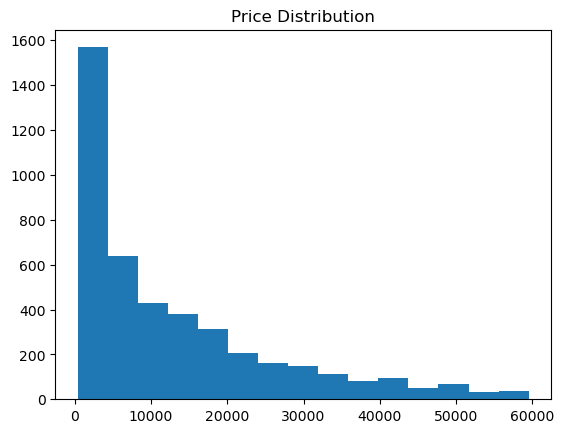

In [372]:
plt.hist(dat1['price'],bins=15)
plt.title('Price Distribution')

<Axes: xlabel='price', ylabel='Density'>

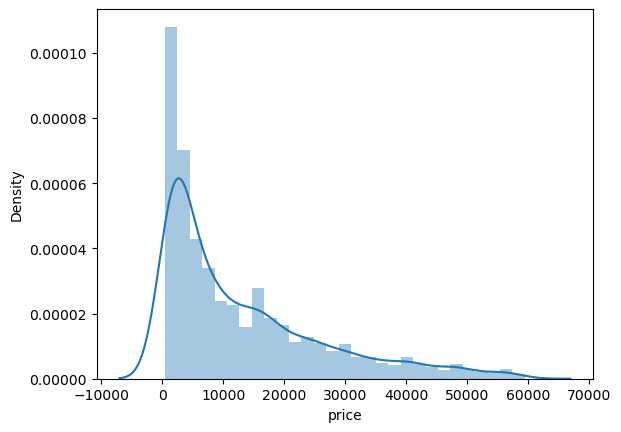

In [373]:
sns.distplot(dat1['price'])

Text(0.5, 1.0, 'Relationship Between Price and Bedrooms')

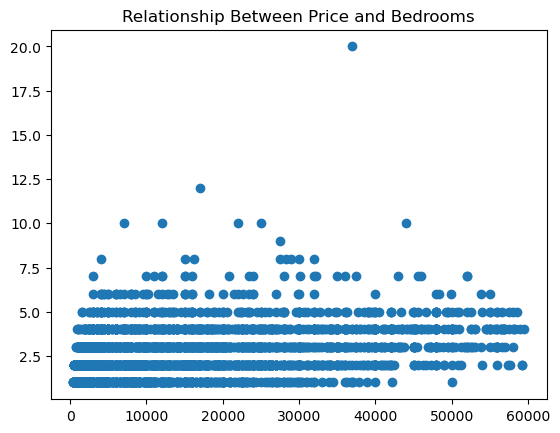

In [374]:
plt.scatter(dat1['price'],dat1['bedrooms'])
plt.title('Relationship Between Price and Bedrooms')

([<matplotlib.axis.XTick at 0x1bb4524e490>], [Text(1, 0, 'Price')])

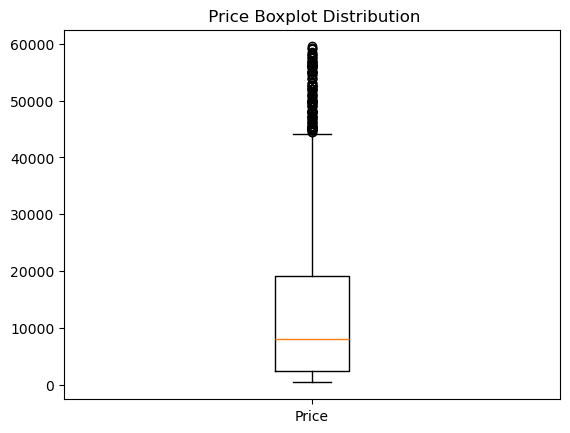

In [375]:
plt.boxplot(dat1['price'])
plt.title(' Price Boxplot Distribution')
plt.xticks([1],['Price'])

In [376]:
#IQR
Q3=dat1['price'].quantile(.75)
Q1=dat1['price'].quantile(.25)
IQR= Q3-Q1

upper_limit=Q3+1.5*IQR
lower_limit=Q1-1.5*IQR
dat1['price']=np.where(dat1['price']>upper_limit,upper_limit,np.where(dat1['price']<lower_limit,lower_limit,dat1['price']))


([<matplotlib.axis.XTick at 0x1bb452a1d10>], [Text(1, 0, 'Price')])

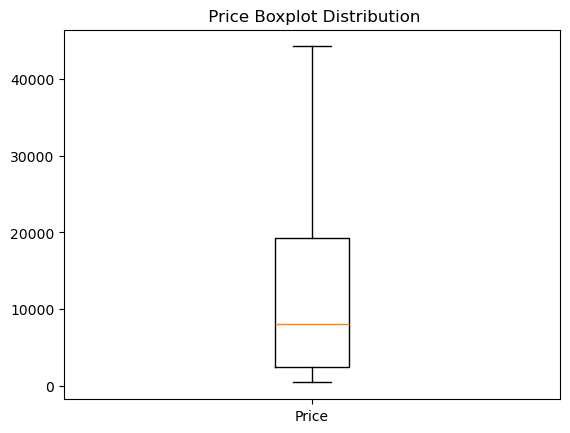

In [377]:
plt.boxplot(dat1['price'])
plt.title(' Price Boxplot Distribution')
plt.xticks([1],['Price'])

<Figure size 1400x1000 with 0 Axes>

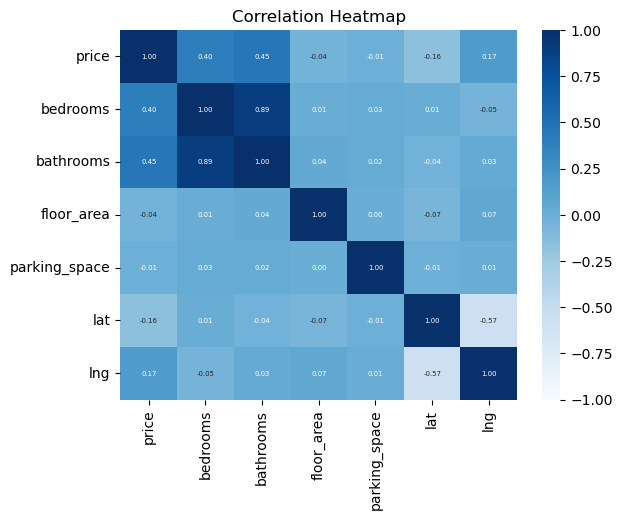

<Figure size 1400x1000 with 0 Axes>

In [378]:
corr=dat1.corr(numeric_only=True)
sns.heatmap(corr,cmap='Blues',annot=True,vmax=1,vmin=-1,annot_kws={'size':5},fmt='.2f')
plt.title('Correlation Heatmap')
plt.figure(figsize=(14,10))

In [379]:
dat1.head()

,date,price,category,bedrooms,bathrooms,floor_area,condition,parking_space,is_furnished,lat,lng
0,2023-02-06,9196.0,Flats,2,2,145,Used,False,Semi-Furnished,5.635828,-0.161359
1,2023-05-22,7500.0,Flats,2,2,100,Used,False,Unfurnished,5.614123,-0.195647
2,2023-05-14,11200.0,Detached,4,5,100,New,False,Semi-Furnished,5.680213,-0.137248
3,2025-04-21,2500.0,Detached,3,3,17,Used,False,Semi-Furnished,5.583166,-0.104608
4,2024-05-09,9146.0,Detached,3,3,160,Used,False,Semi-Furnished,5.637614,-0.126606


In [380]:
from sklearn.preprocessing import LabelEncoder
leb=LabelEncoder()
dat1['category']=leb.fit_transform(dat1['category'])
dat1['condition']=leb.fit_transform(dat1['condition'])
dat1['parking_space']=leb.fit_transform(dat1['parking_space'])
dat1['is_furnished']=leb.fit_transform(dat1['is_furnished'])


In [381]:
dat1['log_price']=np.log(dat1['price'])

<Figure size 1400x1000 with 0 Axes>

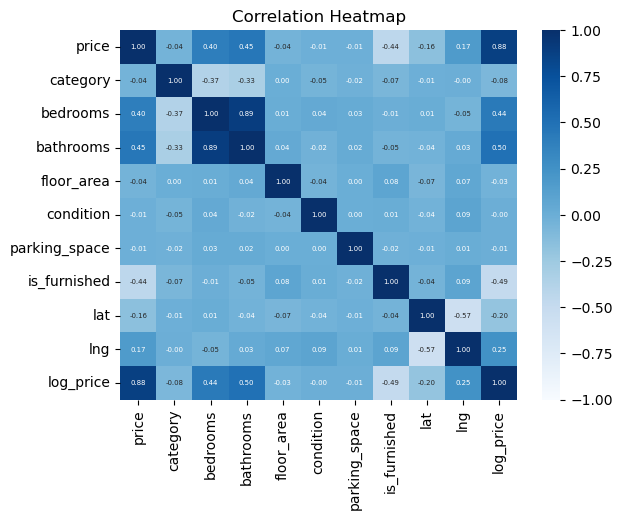

<Figure size 1400x1000 with 0 Axes>

In [382]:
corr=dat1.corr(numeric_only=True)
sns.heatmap(corr,cmap='Blues',annot=True,vmax=1,vmin=-1,annot_kws={'size':5},fmt='.2f')
plt.title('Correlation Heatmap')
plt.figure(figsize=(14,10))

In [383]:
dat1.head()

,date,price,category,bedrooms,bathrooms,floor_area,condition,parking_space,is_furnished,lat,lng,log_price
0,2023-02-06,9196.0,2,2,2,145,2,0,1,5.635828,-0.161359,9.126524
1,2023-05-22,7500.0,2,2,2,100,2,0,2,5.614123,-0.195647,8.922658
2,2023-05-14,11200.0,0,4,5,100,0,0,1,5.680213,-0.137248,9.323669
3,2025-04-21,2500.0,0,3,3,17,2,0,1,5.583166,-0.104608,7.824046
4,2024-05-09,9146.0,0,3,3,160,2,0,1,5.637614,-0.126606,9.121072


In [384]:
#Defining the Target Variable
x=dat1.drop(columns=['price','date','log_price'])
y=dat1['log_price']

In [385]:
#Splitting the dataset
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=0)

In [386]:
model=Pipeline([('scaler',StandardScaler()),('poly',PolynomialFeatures(degree=2,include_bias=False)),('linear',LinearRegression())])

In [387]:
model.fit(x_train,y_train)

,steps,"[('scaler', ...), ('poly', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,2
,interaction_only,False
,include_bias,False
,order,'C'


In [388]:
y_pred=model.predict(x_test)
y_pred

array([ 8.33141112,  8.16157166,  9.27982124,  7.99401336,  9.14502246,
       10.18499138, 10.25751219,  8.74400668,  8.84702815,  7.89938737,
        9.55757945,  6.90533651,  7.33483904,  9.74575555,  9.51491177,
        9.91586516,  9.59547765,  7.6912831 ,  9.62374647,  8.99370524,
        7.18196088,  8.65713923, 10.15417463,  9.25950893,  8.88822885,
        8.611881  , 10.25584735,  9.22084755,  9.42083886,  8.06441781,
        9.46763057,  9.37760581, 10.23589076,  9.02789218,  7.56601932,
        9.52997705,  9.03138348,  8.5891065 ,  6.85525592,  9.4865964 ,
        7.55703051, 10.01039981,  7.25789195,  9.31297104, 10.51435356,
        9.19295732,  8.72699531,  8.98140006,  8.0505409 ,  9.06458449,
        9.7653027 ,  7.90319659, 10.00759089,  8.06781077, 10.22151592,
        9.41410631,  7.80857719,  7.66117662,  9.44987989,  8.55940962,
        8.23167394,  8.59333029,  9.05905333,  8.77181404,  8.88721226,
        9.01477937,  7.11971137,  7.84624081, 10.49605471, 10.65

In [389]:
model.score(x_test,y_test)

0.6539462306295636

In [390]:
MAE=mean_absolute_error(y_test,y_pred)
MAE

0.5424147011378305

In [391]:
MSE=mean_squared_error(y_test,y_pred)
MSE

0.509894324102494

In [392]:
RMSE=np.sqrt(MSE)
RMSE

np.float64(0.7140688510938522)

In [393]:
lasso_pipeline=Pipeline([('scaler',StandardScaler()),('poly',PolynomialFeatures(degree=2,include_bias=False)),('lasso',Lasso(alpha=.05,max_iter=100,tol=0.1))])

In [394]:
lasso_pipeline.fit(x_train,y_train)

,steps,"[('scaler', ...), ('poly', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,2
,interaction_only,False
,include_bias,False
,order,'C'


In [395]:
L1_pred=lasso_pipeline.predict(x_test)
L1_pred

array([ 8.00360756,  8.44092495,  8.90545467,  8.41444436,  8.81134101,
       10.00674498,  9.7400697 ,  8.76973124,  8.56553506,  8.39135867,
        9.58561968,  7.38358168,  7.25015475,  9.66713902,  9.47546206,
        9.6281995 ,  9.61793943,  7.81336356,  9.39085573,  9.379616  ,
        7.78934048,  8.91695739, 10.04287258,  8.88897812,  8.77890559,
        8.94868007, 10.15075285,  9.49382973,  9.25167554,  7.91640844,
        9.24981503,  9.25894426, 10.03400855,  8.80082605,  7.73413443,
        9.5573801 ,  8.80641181,  8.96961005,  7.20989663,  9.26221987,
        7.9159714 ,  9.70776801,  7.2801031 ,  9.27990607, 10.45611418,
        9.19934865,  9.05815026,  9.16969711,  7.86379787,  8.79257586,
        9.38619751,  8.80302159,  9.68471429,  7.91655371, 10.19701571,
        9.14497351,  9.00911054,  7.95018668,  9.26095019,  8.56865001,
        7.99894078,  8.27856081,  8.79552152,  9.07771316,  8.79392711,
        8.8249649 ,  7.84153308,  8.4147044 , 10.46267438, 10.88

In [396]:
lasso_pipeline.score(x_test,y_test)

0.5870530923826075

In [397]:
MAE_lasso=mean_absolute_error(y_test,L1_pred)
MAE_lasso

0.6257197422375446

In [398]:
MSE_lasso=mean_squared_error(y_test,L1_pred)
MSE_lasso

0.6084582888169331

In [399]:
RMSE_lasso=np.sqrt(MSE_lasso)
RMSE_lasso

np.float64(0.7800373637313364)

In [400]:
#model pvalues
X=sm.add_constant(x)
pv=sm.OLS(y,X).fit()
pv.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              log_price   R-squared:                       0.553
Model:                            OLS   Adj. R-squared:                  0.552
Method:                 Least Squares   F-statistic:                     592.7
Date:                Tue, 04 Aug 2026   Prob (F-statistic):               0.00
Time:                        19:41:42   Log-Likelihood:                -5249.1
No. Observations:                4320   AIC:                         1.052e+04
Df Residuals:                    4310   BIC:                         1.058e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             9.3518      0.175     53.538      0.000       9.009       9.694
category          0.0531      0.012      4.393      0.000       0.029       0.077
bedrooms          0.1684      0.022      7.490      0.000       0.124       0.212
bathrooms         0.2794      0.020     13.778      0.000       0.240       0.319
floor_area    -4.323e-05   1.47e-05     -2.943      0.003    -7.2e-05   -1.44e-05
condition        -0.0281      0.013     -2.192      0.028      -0.053      -0.003
parking_space    -1.2100      0.409     -2.960      0.003      -2.011      -0.409
is_furnished     -0.7341      0.015    -47.743      0.000      -0.764      -0.704
lat              -0.1654      0.030     -5.471      0.000      -0.225      -0.106
lng               0.8201      0.041     20.167      0.000       0.740       0.900
==============================================================================
Omnibus:                      214.226   Durbin-Watson:                   1.925
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              375.023
Skew:                          -0.393   Prob(JB):                     3.67e-82
Kurtosis:                       4.210   Cond. No.                     3.20e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.2e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [401]:
pv.pvalues

const            0.000000e+00
category         1.147310e-05
bedrooms         8.277138e-14
bathrooms        2.699570e-42
floor_area       3.272517e-03
condition        2.846027e-02
parking_space    3.091264e-03
is_furnished     0.000000e+00
lat              4.735595e-08
lng              1.674500e-86
dtype: float64

# Time Series Model

In [402]:
tdf=df[['date','price']]
tdf.head()

,date,price
0,2023-02-06,9196
1,2023-05-22,7500
2,2023-05-14,11200
3,2025-04-21,2500
4,2024-05-09,9146


In [403]:
tdf.set_index('date')

,price
date,
2023-02-06,9196
2023-05-22,7500
2023-05-14,11200
2025-04-21,2500
2024-05-09,9146
...,...
2024-05-23,15600
2023-03-31,39568
2024-02-01,20000


<Axes: >

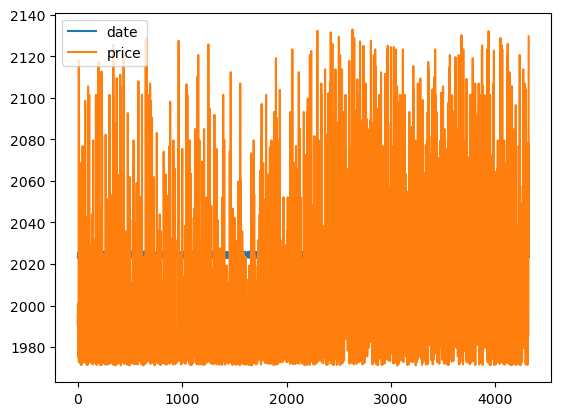

In [404]:

#NO trend and seasonality.Therefore use simple exponential smoothimg and simple moving average
tdf.plot()

# SImple Moving Average

In [405]:
#Using  60 day SMA
tdf['SMA_60']=tdf['price'].rolling(window=60).mean()

<Axes: >

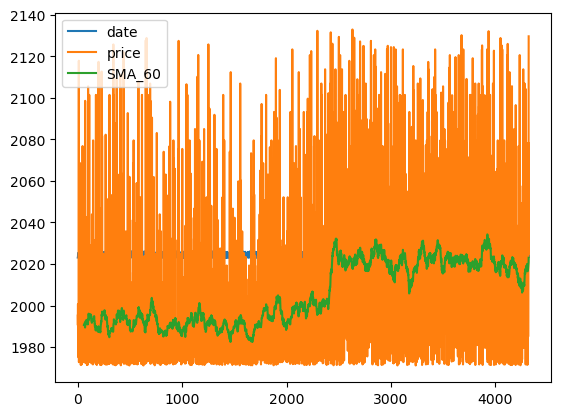

In [406]:
tdf.plot()

In [407]:
#forecasting the next 2 tears where 360 days make a year

In [408]:
last_date=tdf['date'].iloc[-1]
last_SMA=tdf['SMA_60'].iloc[-1]

future_dates=pd.date_range(start=last_date,periods=721)[1:]
forecast=pd.DataFrame({'Forecast':[last_SMA]*720},index=future_dates)

In [409]:
forecast.head()

,Forecast
2023-12-30,19358.983333
2023-12-31,19358.983333
2024-01-01,19358.983333
2024-01-02,19358.983333
2024-01-03,19358.983333


In [410]:
actual=tdf['price'].iloc[59:].values
predi=tdf['SMA_60'].dropna().values

In [411]:
Mae=mean_absolute_error(actual,predi)
Mae

9105.020175232732

In [412]:
Mse=mean_squared_error(actual,predi)
Mse

147687446.83965552

Text(0.5, 1.0, 'Actual Vrs Predicted Outcome')

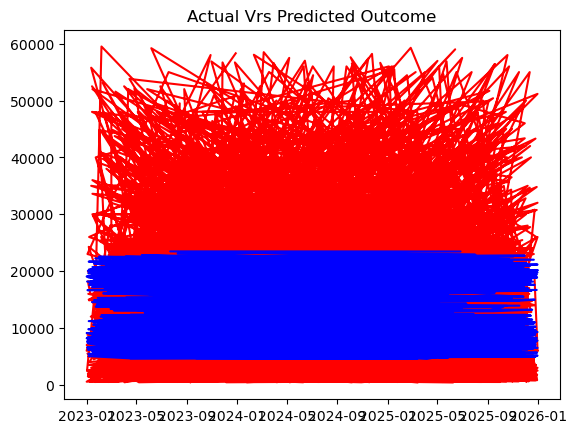

In [413]:
plt.plot(tdf['date'].iloc[59:],actual,label='actual',color='red')
plt.plot(tdf['date'].iloc[59:],predi,label='predicted',color='blue')
plt.title('Actual Vrs Predicted Outcome')

# Simple Exponential Smoothing

In [414]:
SES_model=SimpleExpSmoothing(tdf['price']).fit()

In [415]:
SES_model.summary()

Dep. Variable:,price,No. Observations:,4320
Model:,SimpleExpSmoothing,SSE,651669561156.213
Optimized:,True,AIC,81357.345
Trend:,None,BIC,81370.087
Seasonal:,None,AICC,81357.354
Seasonal Periods:,None,Date:,"Tue, 04 Aug 2026"
Box-Cox:,False,Time:,19:42:05
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.0109747,alpha,True
initial_level,9196.0000,l.0,False
